# 과제 4 — Diffusion Policy 학습 및 ACT 비교

**과제 내용**: 과제 3과 같은 데이터셋으로 Diffusion Policy를 학습하고, 실제 로봇에서 10회 평가해 과제 3의 ACT 정책과 성공률·동작의 부드러움·반응성을 비교한다. 같은 Diffusion Policy를 DDIM 스케줄러로 denoising 횟수만 10으로 줄여 10회 더 평가하고, denoising 횟수가 성공률과 실시간성에 주는 영향을 분석한다. 학습된 정책은 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1~3과 같은 저장소, assignments 폴더)에 `assignment_4.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고, 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- Diffusion Policy는 과제 3의 ACT와 **같은 학습 데이터셋**으로 학습해야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 비교 대상 ACT는 과제 3에서 성공률이 가장 높았던 chunk_size의 정책을 쓴다. 과제 3 이후 평가 환경(조명, 카메라 위치, 물체 위치 표시)이 바뀌지 않았다면 과제 3의 ACT 평가 결과를 **재사용해도 된다.** 바뀌었다면 ACT도 다시 10회 평가한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [25]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136028"
NAME = "김용진"
HF_USER = "Rlayd36"

TASK = "Red block pickup and place"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube_20261116_142939"   # 과제 3과 같은 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)

# 비교 대상 ACT 정책 (과제 3에서 성공률이 가장 높았던 chunk_size)
ACT_CHUNK_SIZE = 50   # 과제 3에서 chunk10과 chunk50이 20%로 공동 1위 -> 시작 자세 정지 문제가 없던 chunk50 선택
ACT_POLICY_REPO = f"{HF_USER}/act_redblock_chunk{ACT_CHUNK_SIZE}"

# Diffusion Policy
DP_POLICY_REPO = f"{HF_USER}/diffusion_redblock"

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 그대로 적을 것 (ACT 평가를 재사용하면 과제 3의 평가 데이터셋 repo를 그대로 적는다)
CONDITIONS = ["act", "dp", "dp_ddim10"]
LABELS = {"act": f"ACT (chunk{ACT_CHUNK_SIZE})", "dp": "DP (DDPM)", "dp_ddim10": "DP (DDIM 10)"}
EVAL_DATASETS = {
    "act":       f"{HF_USER}/rollout_act_redblock_chunk50_20261116_235433",   # 과제 3 평가 재사용
    "dp":        f"{HF_USER}/rollout_diffusion_redblock_20261121_164339",          # 평가 후 실제 이름으로 교체
    "dp_ddim10": f"{HF_USER}/rollout_diffusion_redblock_ddim10_20261121_165411",   # 평가 후 실제 이름으로 교체
}
WANDB_URL = "https://forge.coreweave.com/wandb/rlayd36-korea-university-of-technology-and-education/lerobot"   # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("ACT 정책      :", f"https://huggingface.co/{ACT_POLICY_REPO}")
print("DP 정책       :", f"https://huggingface.co/{DP_POLICY_REPO}")
for k in CONDITIONS:
    print(f"{LABELS[k]:<14} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136028 김용진
태스크        : Red block pickup and place
학습 데이터셋 : https://huggingface.co/datasets/Rlayd36/pick-cube_20261116_142939
ACT 정책      : https://huggingface.co/Rlayd36/act_redblock_chunk50
DP 정책       : https://huggingface.co/Rlayd36/diffusion_redblock
ACT (chunk50)  평가 : https://huggingface.co/datasets/Rlayd36/rollout_act_redblock_chunk50_20261116_235433
DP (DDPM)      평가 : https://huggingface.co/datasets/Rlayd36/rollout_diffusion_redblock_20261121_164339
DP (DDIM 10)   평가 : https://huggingface.co/datasets/Rlayd36/rollout_diffusion_redblock_ddim10_20261121_165411
wandb         : https://forge.coreweave.com/wandb/rlayd36-korea-university-of-technology-and-education/lerobot


In [26]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [27]:
# Hub 접근 확인 — 6개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (ACT_POLICY_REPO, "model"), (DP_POLICY_REPO, "model")]
checks += [(EVAL_DATASETS[k], "dataset") for k in CONDITIONS]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] Rlayd36/pick-cube_20261116_142939  (파일 9개)
OK   [model  ] Rlayd36/act_redblock_chunk50  (파일 9개)
OK   [model  ] Rlayd36/diffusion_redblock  (파일 9개)
OK   [dataset] Rlayd36/rollout_act_redblock_chunk50_20261116_235433  (파일 9개)
OK   [dataset] Rlayd36/rollout_diffusion_redblock_20261121_164339  (파일 9개)
OK   [dataset] Rlayd36/rollout_diffusion_redblock_ddim10_20261121_165411  (파일 9개)


## 1. 실험 설계

### 1-1. 배경
Diffusion Policy는 행동을 한 번에 회귀하지 않는다. 가우시안 노이즈에서 출발해 노이즈를 조금씩 걷어내며(denoising) 행동 시퀀스를 만든다. 학습할 때는 행동에 섞인 노이즈를 맞히도록 배우고, 추론할 때는 이 과정을 `num_inference_steps`번 반복한다.

- `n_obs_steps`: 정책에 넣는 과거 관측 프레임 수
- `horizon`: 한 번의 추론으로 생성하는 행동 시퀀스의 길이
- `n_action_steps`: 생성한 시퀀스 중 실제로 실행하는 스텝 수. 이만큼 실행한 뒤 다시 추론한다.

ACT와 비교하면 다음과 같다.
- ACT는 행동을 L1 손실로 직접 회귀한다. 같은 상황에서 시연이 여러 갈래로 나뉘면(예: 물체를 왼쪽에서 잡기도 하고 오른쪽에서 잡기도 함) 회귀 출력은 그 평균 쪽으로 끌려가기 쉽다. ACT는 CVAE 구조로 이 문제를 일부 완화한다.
- Diffusion Policy는 행동 분포에서 샘플링하므로 여러 갈래의 시연을 그대로 표현할 수 있다. 대신 추론할 때마다 denoising을 여러 번 반복해야 하므로 느리다.
- 학습에 쓴 DDPM 스케줄러 대신 DDIM 스케줄러를 쓰면 **재학습 없이** denoising 횟수를 줄여 추론을 빠르게 할 수 있다. 다만 횟수를 너무 줄이면 행동의 품질이 떨어질 수 있다.

아래 셀은 학습한 정책의 설정을 데이터셋의 fps로 환산해 초 단위로 보여준다.

In [28]:
# 학습 데이터셋의 fps로 관측·행동 구간 길이 환산
import pandas as pd
import matplotlib.pyplot as plt

def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
dp_cfg = load_json(DP_POLICY_REPO, "config.json") or {}
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for key in ["n_obs_steps", "horizon", "n_action_steps"]:
        v = dp_cfg.get(key)
        if v:
            print(f"{key:<15} = {v:>3d} -> {v/fps:5.2f} s")
    if dp_cfg.get("n_action_steps"):
        n_plan = ep_len_s * fps / dp_cfg["n_action_steps"]
        print(f"\n평균 에피소드 한 번에 약 {n_plan:.0f}회 다시 추론한다.")

fps: 30, 에피소드 수: 50, 평균 에피소드 길이: 19.5 s

n_obs_steps     =   2 ->  0.07 s
horizon         =  64 ->  2.13 s
n_action_steps  =  32 ->  1.07 s

평균 에피소드 한 번에 약 18회 다시 추론한다.


### 1-2. 가설 (학습 전에 작성)
결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

비교 기준: 과제 3의 ACT(chunk50)는 성공률 20%였고, 실패 8회 중 7회가 "블록이 아닌 잘못된 위치로 팔을 뻗음"이었다. 같은 데이터셋에서 chunk100에 temporal ensemble을 적용하면 40%까지 올라갔다.

- **성공률이 가장 높을 것으로 예상하는 조건과 이유: DP (DDPM)**
  ACT의 주된 실패는 블록 위치를 제대로 겨냥하지 못하고 엉뚱한 곳으로 가는 것이었다. Diffusion Policy는 행동 분포에서 샘플링하므로 한 갈래의 궤적을 골라 그대로 따라갈 수 있다.

- **동작이 가장 부드러울 것으로 예상하는 조건과 이유: ACT (chunk50)**
  ACT는 50스텝짜리 연속 궤적을 한 번에 실행하므로 청크 안에서는 매끄럽다. 

- **denoising 횟수를 10으로 줄였을 때 성공률과 동작이 어떻게 달라질지와 이유**
  DDIM 10은 추론 시간이 줄어 다시 추론할 때 멈칫하는 현상은 줄어들 것이다. 하지만 생성된 행동에 잔여 노이즈가 남아, 궤적이 조금 흔들리거나 파지 위치가 덜 정확해질 수 있다. 따라서 동작의 끊김은 줄지만 성공률은 DDPM과 같거나 약간 낮을 것으로 예상한다.


### 1-3. 정책 설정 확인
아래 셀은 Diffusion Policy의 주요 설정을 출력하고, ACT와 같은 학습 데이터셋을 썼는지 확인한다.

In [29]:
act_tc = load_json(ACT_POLICY_REPO, "train_config.json") or {}
dp_tc = load_json(DP_POLICY_REPO, "train_config.json") or {}

print("[Diffusion Policy 주요 설정]")
for key in ["type", "n_obs_steps", "horizon", "n_action_steps", "noise_scheduler_type",
            "num_train_timesteps", "num_inference_steps", "crop_shape", "vision_backbone"]:
    print(f"  {key:<22}: {dp_cfg.get(key)}")
if dp_cfg and dp_cfg.get("num_inference_steps") is None:
    print("  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다")

cmp_df = pd.DataFrame([
    {"policy": "ACT", "dataset": act_tc.get("dataset", {}).get("repo_id"),
     "steps": act_tc.get("steps"), "batch_size": act_tc.get("batch_size"), "seed": act_tc.get("seed")},
    {"policy": "Diffusion", "dataset": dp_tc.get("dataset", {}).get("repo_id"),
     "steps": dp_tc.get("steps"), "batch_size": dp_tc.get("batch_size"), "seed": dp_tc.get("seed")},
]).set_index("policy")
display(cmp_df)

same_dataset = cmp_df["dataset"].nunique(dropna=False) == 1 and cmp_df["dataset"].notna().all()
print(("[일치]   " if same_dataset else "[불일치] ") + "학습 데이터셋")
print(("[일치]   " if dp_cfg.get("type") == "diffusion" else "[불일치] ") + f"정책 종류: {dp_cfg.get('type')}")

[Diffusion Policy 주요 설정]
  type                  : diffusion
  n_obs_steps           : 2
  horizon               : 64
  n_action_steps        : 32
  noise_scheduler_type  : DDPM
  num_train_timesteps   : 100
  num_inference_steps   : None
  crop_shape            : [432, 576]
  vision_backbone       : resnet18
  -> num_inference_steps가 None이면 num_train_timesteps만큼 denoising한다


,dataset,steps,batch_size,seed
policy,,,,
ACT,Rlayd36/pick-cube_20261116_142939,100000,8,1000
Diffusion,Rlayd36/pick-cube_20261116_142939,100000,8,1000


[일치]   학습 데이터셋
[일치]   정책 종류: diffusion


## 2. 학습

### 2-1. 실행한 학습 명령어
실제로 실행한 `lerobot-train` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
nohup lerobot-train \
  --dataset.repo_id=Rlayd36/pick-cube_20261116_142939 \
  --dataset.video_backend=pyav \
  --policy.type=diffusion \
  --policy.crop_shape="[432, 576]" \
  --policy.down_dims="[256, 512, 1024]" \
  --policy.device=cuda \
  --policy.repo_id=Rlayd36/diffusion_redblock \
  --output_dir=/home/work/RobotControlAI/outputs/train/diffusion_redblock \
  --job_name=diffusion_redblock \
  --batch_size=8 \
  --steps=100000 \
  --seed=1000 \
  --num_workers=0 \
  --wandb.enable=true > train_diffusion_redblock.log 2>&1 &
```


### 2-2. 학습 환경
- GPU: NVIDIA H200 (
- 학습 step 수 / batch_size: 100,000 / 8 (과제 3 ACT와 동일)
- 소요 시간 (과제 3의 ACT와 비교): 약 4시간 51분 (4:50:58). ACT chunk50(약 2시간 36분)보다 약 1.9배 오래 걸렸다. 
- 기본값에서 변경한 하이퍼파라미터와 이유:
  - `crop_shape` [84, 84] → [432, 576]: 기본값은 640×480 영상에서 84×84의 작은 영역만 잘라 썼다.
  - `down_dims` [512, 1024, 2048] → [256, 512, 1024]: 세션 RAM 한도(4GiB)에서 기본 모델(약 2.8억 파라미터)은 20K step 체크포인트를 저장하는 중 메모리 부족(OOM)으로 종료되었다. U-Net 채널을 절반으로 줄여 89M 파라미터로 학습했다.
  - `num_workers` 4 → 0: 데이터로더 워커 프로세스마다 RAM을 따로 써서 4GiB 한도를 넘었다(OOM).


### 2-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw4.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw4.png)

loss는 처음 약 0.75에서 시작해 1~2K step 안에 0.05 아래로 급격히 떨어졌다. 이후 10K step 무렵부터 0.01~0.02 수준에서 완만하게 감소했고, 100K step에서 0.006으로 끝났다. 끝까지 발산이나 급격한 튐 없이 안정적으로 수렴했다. 단, 이 loss는 무작위 timestep에서 노이즈를 얼마나 잘 예측하는지를 나타내는 MSE이다. 값이 작다고 실제 행동 성공률이 높다는 뜻은 아니어서 실로봇 평가로 확인해야 한다.

In [30]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 둘째 열 loss (열 이름은 본인 파일에 맞게 수정)
import os

CSV_PATH = "images/loss_hw4.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Diffusion Policy training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [31]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# Diffusion Policy는 노이즈 예측 오차(MSE)를 loss로 출력한다
dp_final_loss = 0.006  # step 100K 로그 (ACT chunk50 l1_loss 0.042와는 loss 정의가 달라 직접 비교 불가)
print("Diffusion Policy 최종 loss:", dp_final_loss)

Diffusion Policy 최종 loss: 0.006


## 3. 실로봇 평가 (조건별 10회)

### 3-1. 평가 프로토콜
1. 과제 3에서 표시한 물체 시작 위치 10곳을 그대로 쓴다. **세 조건 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준은 과제 3과 같게 두고 아래에 다시 적는다. 평가 도중 바꾸지 않는다.

성공 기준 (과제 3과 동일)
- 성공: 그리퍼로 빨간 블록을 집어 들어 올린 뒤 목표 위치(박스 안)에 내려놓고 그리퍼를 열어 블록을 놓는 것까지 제한 시간 안에 완료한다. 사람의 개입은 없다. 블록이 목표 위치 안에 정지해 있으면 성공으로 본다.
- 실패: 아래 중 하나라도 해당하면 실패다.
  - 블록을 집지 못함(빈 그리퍼, 블록을 밀어내기만 함)
  - 옮기는 도중 블록을 떨어뜨림
  - 목표 위치 밖에 내려놓음
  - 제한 시간 안에 끝내지 못함(같은 자리에서 머뭇거림 포함)
  - 로봇이 테이블·박스에 부딪히는 등 위험한 동작을 해서 사람이 멈춤
- 에피소드 제한 시간(초): 30초
- ACT 평가 결과 재사용 여부: **재사용**. 과제 3 이후 조명, 카메라 위치, 물체 위치 표시를 바꾸지 않았으므로 과제 3의 chunk50 평가(`rollout_act_redblock_chunk50_20261116_235433`)를 그대로 쓴다.

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).
- Diffusion Policy는 추론이 무겁다. GPU가 있는 PC에서 돌리고, 필요하면 `--device=cuda`를 명시한다.

평가에 실제로 사용한 `lerobot-rollout` 명령어를 붙여 넣는다. DP (DDIM 10)은 같은 정책에 추론 설정만 덮어써서 평가한다. ACT를 다시 평가했다면 그 명령어도 함께 붙여 넣는다.

```bash
# DP (DDPM)
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=Rlayd36/diffusion_redblock \
  --policy.device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=Rlayd36/rollout_diffusion_redblock \
  --dataset.single_task="Red block pickup and place" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15

# DP (DDIM 10)
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=Rlayd36/diffusion_redblock \
  --policy.device=cuda \
  --policy.noise_scheduler_type=DDIM \
  --policy.num_inference_steps=10 \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --teleop.type=so101_leader \
  --teleop.port=/dev/ttyACM1 \
  --teleop.id=my_leader \
  --dataset.repo_id=Rlayd36/rollout_diffusion_redblock_ddim10 \
  --dataset.single_task="Red block pickup and place" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15

# ACT (chunk50): 과제 3 평가 재사용, 다시 실행하지 않음
```

In [33]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CONDITIONS:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"{LABELS[k]:<14} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f" {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

ACT (chunk50)  에피소드 10개, 프레임 8204, fps 30  -> 통과
DP (DDPM)      에피소드 10개, 프레임 4346, fps 30  -> 통과
DP (DDIM 10)   에피소드 10개, 프레임 7013, fps 30  -> 통과
 act 이름 규칙: 통과
 dp 이름 규칙: 통과
 dp_ddim10 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다. ACT 평가를 재사용했다면 과제 3의 결과를 그대로 옮긴다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. 추론 때문에 동작이 멈칫하는 구간이 보이면 함께 적는다. (예: "큐브 위치를 놓침", "다시 추론할 때마다 팔이 잠깐 멈춤", "파지 직전 좌우로 머뭇거림")

In [34]:
def blank():
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

results = {
    "act": [   # 과제 3 chunk50 결과 재사용
            {"episode": 0, "position": 1, "success": True, "smooth": 3, "note": ""},
            {"episode": 1, "position": 2, "success": True, "smooth": 3, "note": ""},
            {"episode": 2, "position": 3, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 3, "position": 4, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 4, "position": 5, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 5, "position": 6, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 6, "position": 7, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 7, "position": 8, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 8, "position": 9, "success": False, "smooth": 3, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
            {"episode": 9, "position": 10, "success": False, "smooth": 3, "note": "블록 위치까지 정상적으로 갔으나 그리퍼가 집는 도중 블록에 걸려 파지 실패"},
    ],
    "dp": [
        {"episode": 0, "position": 1, "success": True, "smooth": 1, "note": ""},
        {"episode": 1, "position": 2, "success": False, "smooth": 1, "note": "블록을 잘 집었지만 집은 상태로 시간 초과(30초)"},
        {"episode": 2, "position": 3, "success": False, "smooth": 1, "note": "블록을 잘 집었지만 집은 상태로 시간 초과(30초)"},
        {"episode": 3, "position": 4, "success": False, "smooth": 1, "note": "그리퍼가 블록을 집지 못함"},
        {"episode": 4, "position": 5, "success": False, "smooth": 1, "note": "블록이 아닌 잘못된 위치로 팔을 뻗음"},
        {"episode": 5, "position": 6, "success": False, "smooth": 1, "note": "블록 위에서 그리퍼 위치를 계속 조정하다가 시간 초과(30초)"},
        {"episode": 6, "position": 7, "success": False, "smooth": 1, "note": "블록 위에서 그리퍼 위치를 계속 조정하다가 시간 초과(30초)"},
        {"episode": 7, "position": 8, "success": False, "smooth": 1, "note": "블록 위에서 그리퍼 위치를 계속 조정하다가 시간 초과(30초)"},
        {"episode": 8, "position": 9, "success": False, "smooth": 1, "note": "블록 위에서 그리퍼 위치를 계속 조정하다가 시간 초과(30초)"},
        {"episode": 9, "position": 10, "success": True, "smooth": 1, "note": ""},
    ],
    "dp_ddim10": [
        {"episode": 0, "position": 1, "success": True, "smooth": 4, "note": ""},
        {"episode": 1, "position": 2, "success": True, "smooth": 4, "note": ""},
        {"episode": 2, "position": 3, "success": True, "smooth": 4, "note": ""},
        {"episode": 3, "position": 4, "success": True, "smooth": 4, "note": ""},
        {"episode": 4, "position": 5, "success": True, "smooth": 4, "note": ""},
        {"episode": 5, "position": 6, "success": True, "smooth": 4, "note": ""},
        {"episode": 6, "position": 7, "success": True, "smooth": 4, "note": ""},
        {"episode": 7, "position": 8, "success": True, "smooth": 4, "note": ""},
        {"episode": 8, "position": 9, "success": True, "smooth": 4, "note": ""},
        {"episode": 9, "position": 10, "success": True, "smooth": 4, "note": ""},
    ],
}
# 예시: results["dp"][0] = {"episode": 0, "position": 1, "success": True, "smooth": 4, "note": "다시 추론할 때 짧게 멈추지만 안정적으로 파지"}

res_df = pd.concat([pd.DataFrame(v).assign(condition=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("condition", sort=False)
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary.index = [LABELS[k] for k in summary.index]
summary

,success_rate,mean_smooth
ACT (chunk50),20.0,3.0
DP (DDPM),20.0,1.0
DP (DDIM 10),100.0,4.0


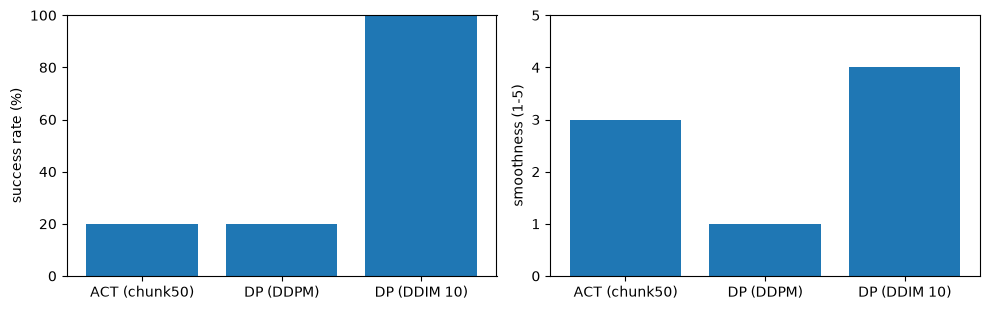

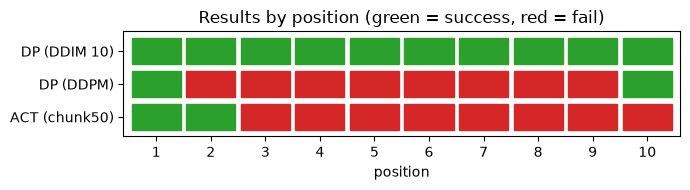

In [35]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
labels = list(summary.index)
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = 조건, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CONDITIONS):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CONDITIONS) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CONDITIONS)))
ax.set_yticklabels([LABELS[k] for k in CONDITIONS]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
과제 3의 3-4와 같은 방법으로, DP (DDPM)과 DP (DDIM 10)을 각각 3회씩 추가로 시도한다. 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮기고**, 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음) ACT는 과제 3의 반응성 테스트 결과와 비교한다.

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다. DDIM 10은 `--policy.noise_scheduler_type=DDIM --policy.num_inference_steps=10`을 함께 준다.

`[작성]` 아래 `reactivity`를 채운다.

In [36]:
reactivity = {
    "dp": [
        {"trial": 0, "followed": False, "note": "옮긴 위치를 따라가지 못함"},
        {"trial": 1, "followed": False, "note": "옮긴 위치를 따라가지 못함"},
        {"trial": 2, "followed": True,  "note": ""},
    ],
    "dp_ddim10": [
        {"trial": 0, "followed": True, "note": ""},
        {"trial": 1, "followed": True, "note": ""},
        {"trial": 2, "followed": True, "note": ""},
    ],
}
react_df = pd.concat([pd.DataFrame(v).assign(condition=LABELS[k]) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("condition", sort=False)["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/3"))
react_df

condition
DP (DDPM)       1/3
DP (DDIM 10)    3/3
Name: followed, dtype: object


,trial,followed,note,condition
0,0,False,옮긴 위치를 따라가지 못함,DP (DDPM)
1,1,False,옮긴 위치를 따라가지 못함,DP (DDPM)
2,2,True,,DP (DDPM)
3,0,True,,DP (DDIM 10)
4,1,True,,DP (DDIM 10)
5,2,True,,DP (DDIM 10)


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
ACT와 Diffusion Policy의 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: ACT의 청크 경계 튐, DP의 추론 중 멈칫함, DDIM 10의 궤적 흔들림)

![act](images/hw4_act.gif)
![dp](images/hw4_dp.gif)
![dp_ddim10](images/hw4_dp_ddim10.gif)

## 4. 고찰

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

성공률은 DP (DDIM 10)이 100%로 가장 높았다. ACT와 DDPM은 둘 다 20%였다. 가설에서는 DDPM이 가장 높고 DDIM 10은 잔여 노이즈 때문에 같거나 약간 낮을 것으로 예상했는데, 결과는 반대였다. DDPM의 실패 8회 중 "잘못된 위치로 감"은 1회뿐이었다. 나머지는 블록까지는 갔지만 그 위에서 그리퍼 위치를 계속 조정하거나, 집은 채로 움직이지 못해 시간 초과로 끝났다. 즉 DDPM은 정책이 무엇을 할지는 알았지만, 100번 denoising하는 추론이 느려서 30초 안에 동작을 끝내지 못했다. 한편 DDIM 10에서 우려했던 잔여 노이즈는 파지 정확도에 눈에 띄는 영향을 주지 않았다. 따라서 가설이 틀린 이유는 실시간 제어에서 추론 속도가 미치는 영향을 과소평가한 데 있다.

**4-2. 행동 생성 방식의 차이** — ACT와 Diffusion Policy의 동작에서 관찰된 차이(궤적의 부드러움, 머뭇거림, 파지 위치 선택 등)를 두 정책의 행동 생성 방식(회귀와 샘플링)으로 설명하라.

ACT의 실패 8회 중 7회는 "블록이 아닌 잘못된 위치로 팔을 뻗음"이었다. 반면 DP는 두 조건을 합친 20회 중 이런 실패가 1회뿐이었다. ACT는 L1 회귀로 행동 청크를 한 번에 출력한다. 그래서 학습 데이터에 블록 위치별로 서로 다른 궤적이 섞여 있으면 그 평균 쪽으로 끌려가, 실제 블록이 아닌 곳을 겨냥할 수 있다. Diffusion Policy는 노이즈에서 시작해 행동 분포의 한 모드를 샘플링하므로, 현재 관측에 맞는 궤적 하나를 골라 블록 위치를 더 정확히 찾았다. 부드러움은 ACT 3점, DDIM 10 4점, DDPM 1점이었다. 샘플링 방식 자체보다 다시 추론하는 데 걸리는 시간이 부드러움을 좌우한 것으로 보인다.

**4-3. denoising 횟수와 실시간성** — DDIM 10에서 성공률, 부드러움, 추론 때문에 멈칫하는 정도가 DDPM과 비교해 어떻게 달라졌는가? 실시간 제어 관점에서 적절한 denoising 횟수는 얼마라고 보는가?

denoising을 100회에서 10회로 줄이자 성공률은 20%에서 100%로, 부드러움은 1점에서 4점으로 크게 좋아졌다. DDPM은 행동 8개를 실행할 때마다 U-Net을 100번 돌려야 해서, 다음 행동이 나올 때까지 로봇이 기다리는 시간이 길었다. 그 결과 동작이 끊기고, 블록 위에서 미세하게 조정하는 구간에서는 시간 초과가 반복되었다. DDIM 10은 추론 계산량이 약 1/10이라 멈칫하는 시간이 크게 줄었고, 잔여 노이즈로 인한 궤적 흔들림도 성공에 지장을 줄 정도는 아니었다. 실시간 제어에서는 한 번 추론하는 시간이 행동 8개를 실행하는 시간보다 짧아야 로봇이 기다리지 않는다.

**4-4. 반응성** — Diffusion Policy는 `n_action_steps`마다 다시 추론한다. 반응성 테스트 결과를 과제 3의 ACT 결과와 비교하고, 차이를 다시 추론하는 주기로 설명하라.

반응성 테스트에서 블록을 옮긴 위치를 따라간 비율은 DDIM 10 100%, DDPM 33.33% 이었다. 과제 3의 ACT은 30% 이었다. ACT chunk50은 50스텝의 청크를 다 실행한 뒤에야 새 관측을 반영하므로, 그 사이 블록이 옮겨지면 옛 위치로 계속 간다. DP는 8스텝마다 다시 추론하므로 원래는 새 위치를 훨씬 빨리 반영할 수 있다. 실제로 DDIM 10은 추론이 빨라 이 짧은 주기가 그대로 지켜져서 모두 따라갔다. DDPM은 추론 시간이 길어 실제로 다시 추론하는 주기가 늘어났고, 옮긴 위치를 따라가지 못하는 경우가 많았다. 즉 반응성은 스텝 수와 추론 시간을 합친 실제 다시 추론하는 주기로 결정된다.

**4-5. 내 태스크에 맞는 정책** — 학습 시간, 추론 속도, 성공률을 함께 고려할 때 본인 태스크에는 ACT와 Diffusion Policy 중 무엇이 적합한가? 그 정책을 더 개선하려면 무엇을 바꿔 보겠는가?

본인 태스크에는 DDIM 10으로 추론하는 Diffusion Policy가 적합하다. 학습 시간은 약 4시간 51분으로 ACT chunk50보다 길었다. 하지만 이는 RAM 4GiB 제약 때문에 `num_workers=0`으로 학습해 데이터 로딩이 병목이 된 영향이 크다. 결정적으로 성공률과 반응성에서 차이가 크고, 학습은 한 번이면 된다. 추론도 DDIM 10이면 실시간 제어에 충분히 빨랐다. 더 개선하려면 먼저 블록 위치를 더 다양하게 바꾼 평가로 일반화 성능을 확인하겠다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [37]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in EVAL_DATASETS.values()),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "Diffusion Policy 업로드됨 (config.json, model.safetensors)": (
        file_ok(DP_POLICY_REPO, "config.json", "model") and file_ok(DP_POLICY_REPO, "model.safetensors", "model")),
    "ACT와 같은 학습 데이터셋 사용 (1-3)": bool(same_dataset),
}
for k in CONDITIONS:
    check_items[f"{LABELS[k]} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"{LABELS[k]} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"{LABELS[k]} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["반응성 테스트 6회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 학습 데이터셋 접근 가능 (public)
[통과] Diffusion Policy 업로드됨 (config.json, model.safetensors)
[통과] ACT와 같은 학습 데이터셋 사용 (1-3)
[통과] ACT (chunk50) 평가 데이터셋 에피소드 10개
[통과] ACT (chunk50) 회차별 결과 10개 입력
[통과] ACT (chunk50) 실패 회차에 원인 기재
[통과] DP (DDPM) 평가 데이터셋 에피소드 10개
[통과] DP (DDPM) 회차별 결과 10개 입력
[통과] DP (DDPM) 실패 회차에 원인 기재
[통과] DP (DDIM 10) 평가 데이터셋 에피소드 10개
[통과] DP (DDIM 10) 회차별 결과 10개 입력
[통과] DP (DDIM 10) 실패 회차에 원인 기재
[통과] 반응성 테스트 6회 입력

모두 통과
